In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
# Dataset paths
ROOT_DIR = Path(r"D:\CloudRemoval_Finetune")

PATCH_ROOT = ROOT_DIR / "patches"
CSV_PATH = PATCH_ROOT / "patch_manifest.csv"

# Dataset configuration
PATCH_SIZE = 256
IN_CHANNELS = 3
BANDS = ["BAND2", "BAND3", "BAND4"]

# Training configuration
BATCH_SIZE = 8
NUM_WORKERS = 0

# Reproducibility
PIN_MEMORY = torch.cuda.is_available()

print("Root directory:", ROOT_DIR)
print("Patch directory:", PATCH_ROOT)
print("CSV manifest:", CSV_PATH)
print("Batch size:", BATCH_SIZE)
print("Patch size:", PATCH_SIZE)

assert CSV_PATH.exists(), "CSV manifest not found!"

Root directory: D:\CloudRemoval_Finetune
Patch directory: D:\CloudRemoval_Finetune\patches
CSV manifest: D:\CloudRemoval_Finetune\patches\patch_manifest.csv
Batch size: 8
Patch size: 256


In [3]:
# Load patch manifest
df = pd.read_csv(CSV_PATH)

# Separate datasets
train_df = df[df["split"] == "train"].reset_index(drop=True)
valid_df = df[df["split"] == "valid"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print("Dataset loaded successfully.")

print(f"Training patches:   {len(train_df):,}")
print(f"Validation patches: {len(valid_df):,}")
print(f"Testing patches:    {len(test_df):,}")

Dataset loaded successfully.
Training patches:   121,479
Validation patches: 26,314
Testing patches:    25,968


In [4]:
from pathlib import Path

PROJECT_ROOT = Path(r"E:\Rasengan\Cloud-Removal")

SRC_DIR = PROJECT_ROOT / "src"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"

print("Source directory exists:", SRC_DIR.exists())
print("Checkpoint directory exists:", CHECKPOINT_DIR.exists())

if SRC_DIR.exists():
    print("\nSource files:")
    for file in SRC_DIR.glob("*.py"):
        print(file.name)

if CHECKPOINT_DIR.exists():
    print("\nAvailable checkpoints:")
    for file in CHECKPOINT_DIR.glob("*.pth"):
        print(file.name, f"({file.stat().st_size / (1024**2):.2f} MB)")

Source directory exists: True
Checkpoint directory exists: True

Source files:
diffusion.py
evaluate.py
model.py
patch_generation.py
sampler.py
train.py

Available checkpoints:
best_model.pth (23.07 MB)
latest_checkpoint.pth (65.26 MB)


In [5]:
BEST_PATH = CHECKPOINT_DIR / "best_model.pth"
LATEST_PATH = CHECKPOINT_DIR / "latest_checkpoint.pth"

best_ckpt = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=True
)

latest_ckpt = torch.load(
    LATEST_PATH,
    map_location="cpu",
    weights_only=False
)

print("BEST MODEL")
print("Type:", type(best_ckpt))

if isinstance(best_ckpt, dict):
    print("Keys:", list(best_ckpt.keys()))

print("\nLATEST CHECKPOINT")
print("Keys:", list(latest_ckpt.keys()))

if isinstance(latest_ckpt, dict):
    for key, value in latest_ckpt.items():
        if isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

BEST MODEL
Type: <class 'dict'>
Keys: ['model', 'epoch', 'best_val_loss']

LATEST CHECKPOINT
Keys: ['model', 'optimizer', 'scaler', 'epoch', 'best_val_loss']
model: dictionary with 308 entries
optimizer: dictionary with 2 entries
scaler: dictionary with 5 entries
epoch: 9
best_val_loss: 0.05409072526691175


In [6]:
from src.model import DiffCRModel

model = DiffCRModel().to(DEVICE)

model.load_state_dict(best_ckpt["model"])

model.eval()

print("Pretrained DiffCR loaded successfully.")
print("Checkpoint epoch:", best_ckpt["epoch"])
print("Best validation loss:", best_ckpt["best_val_loss"])
print("Parameters:", sum(p.numel() for p in model.parameters()))

Pretrained DiffCR loaded successfully.
Checkpoint epoch: 7
Best validation loss: 0.05409072526691175
Parameters: 6019907


In [7]:
import csv
import rasterio

ORIGINAL_MANIFEST = r"D:\data\diffcr_patches\manifest.csv"

with open(ORIGINAL_MANIFEST, "r", encoding="utf-8-sig") as f:
    reader = csv.DictReader(f)
    original_sample = next(reader)

print("Original training sample:")
print(original_sample)

original_path = r"D:\data\diffcr_patches\cloudy\ahemadabad1\r0_c10240.tif"


with rasterio.open(original_path) as src:
    print("\nImage shape:", src.shape)
    print("Band count:", src.count)
    print("Band descriptions:", src.descriptions)
    print("Data types:", src.dtypes)
    print("Band tags:", src.tags(1))

Original training sample:
{'scene': 'ahemadabad1', 'patch': 'r0_c10240', 'cloudy_path': 'E:\\Rasengan\\Cloud-Removal\\data\\diffcr_patches\\cloudy\\ahemadabad1\\r0_c10240.tif', 'clear_path': 'E:\\Rasengan\\Cloud-Removal\\data\\diffcr_patches\\clear\\ahemadabad1\\r0_c10240.tif', 'split': 'test'}

Image shape: (256, 256)
Band count: 3
Band descriptions: ('BAND2.TIF', 'BAND3.TIF', 'BAND4.TIF')
Data types: ('uint16', 'uint16', 'uint16')
Band tags: {}


In [8]:
# Fine-tuning dataset configuration

FINETUNE_CSV = PATCH_ROOT / "patch_manifest.csv"

train_df = pd.read_csv(FINETUNE_CSV)
train_df = train_df.sort_values(
    ["split", "pair_id", "patch_name"]
).reset_index(drop=True)

train_data = train_df[train_df["split"] == "train"].reset_index(drop=True)
val_data = train_df[train_df["split"] == "valid"].reset_index(drop=True)
test_data = train_df[train_df["split"] == "test"].reset_index(drop=True)

print("Fine-tuning dataset configuration")
print("-" * 40)
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

print("\nChannel order: B2, B3, B4")
print("Patch size: 256 × 256")

Fine-tuning dataset configuration
----------------------------------------
Training: 121479
Validation: 26314
Testing: 25968

Channel order: B2, B3, B4
Patch size: 256 × 256


In [9]:
class SatellitePatchDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def read_image(self, path):

        with rasterio.open(path) as src:
            image = src.read().astype(np.float32)

        # Original DiffCR preprocessing
        image = np.clip(image, 0, 1023) / 1023.0
        image = image * 2.0 - 1.0

        return torch.from_numpy(image)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        cloudy = self.read_image(row["cloudy_path"])
        clear = self.read_image(row["clear_path"])

        return cloudy, clear

In [10]:
BATCH_SIZE = 8
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"

# Create datasets
train_dataset = SatellitePatchDataset(train_data)
val_dataset = SatellitePatchDataset(val_data)
test_dataset = SatellitePatchDataset(test_data)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("DataLoaders created successfully.")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully.
Training batches: 15184
Validation batches: 3290
Testing batches: 3246


In [11]:
def sam_loss(prediction, target, eps=1e-8):

    # Convert normalized [-1, 1] values to [0, 1]
    prediction = ((prediction.float() + 1) / 2).clamp(0, 1)
    target = ((target.float() + 1) / 2).clamp(0, 1)

    # Convert (B, C, H, W) to (B, H, W, C)
    prediction = prediction.permute(0, 2, 3, 1)
    target = target.permute(0, 2, 3, 1)

    # Spectral vector magnitudes
    pred_norm = torch.linalg.vector_norm(
        prediction, dim=-1
    )

    target_norm = torch.linalg.vector_norm(
        target, dim=-1
    )

    # Exclude zero-magnitude spectral vectors
    valid = (pred_norm > eps) & (target_norm > eps)

    if not valid.any():
        return prediction.sum() * 0.0

    # Dot product
    dot_product = (prediction * target).sum(dim=-1)

    # Cross product magnitude
    cross_product = torch.linalg.vector_norm(
        torch.cross(prediction, target, dim=-1),
        dim=-1
    )

    # Spectral angle in radians
    angles = torch.atan2(
        cross_product,
        dot_product
    )

    return angles[valid].mean()

In [12]:
def sam_loss(prediction, target, eps=1e-8):

    # Convert normalized [-1, 1] values to [0, 1]
    prediction = ((prediction.float() + 1) / 2).clamp(0, 1)
    target = ((target.float() + 1) / 2).clamp(0, 1)

    # Convert (B, C, H, W) to (B, H, W, C)
    prediction = prediction.permute(0, 2, 3, 1)
    target = target.permute(0, 2, 3, 1)

    # Spectral vector magnitudes
    pred_norm = torch.linalg.vector_norm(
        prediction, dim=-1
    )

    target_norm = torch.linalg.vector_norm(
        target, dim=-1
    )

    # Exclude zero-magnitude spectral vectors
    valid = (pred_norm > eps) & (target_norm > eps)

    if not valid.any():
        return prediction.sum() * 0.0

    # Dot product
    dot_product = (prediction * target).sum(dim=-1)

    # Cross product magnitude
    cross_product = torch.linalg.vector_norm(
        torch.cross(prediction, target, dim=-1),
        dim=-1
    )

    # Spectral angle in radians
    angles = torch.atan2(
        cross_product,
        dot_product
    )

    return angles[valid].mean()

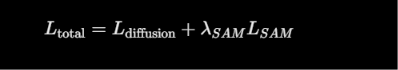

In [13]:
def finetuning_loss(model, diffusion, cloudy, clear, lambda_sam):

    batch_size = clear.shape[0]

    timesteps = torch.randint(
        0,
        diffusion.timesteps,
        (batch_size,),
        device=DEVICE
    )

    noise = torch.randn_like(clear)

    noisy_clear = diffusion.q_sample(
        clear,
        timesteps,
        noise
    )

    model_input = torch.cat(
        [cloudy, noisy_clear],
        dim=1
    )

    predicted_clear = model(
        model_input,
        timesteps
    )

    diffusion_loss = F.l1_loss(
        predicted_clear,
        clear
    )

    spectral_loss = sam_loss(
        predicted_clear,
        clear
    )

    total_loss = diffusion_loss + lambda_sam * spectral_loss

    loss_components = {
        "diffusion_loss": diffusion_loss,
        "sam_loss": spectral_loss,
        "total_loss": total_loss
    }

    return total_loss, loss_components

In [14]:
cloudy_batch, clear_batch = next(iter(train_loader))

cloudy_batch = cloudy_batch.to(DEVICE)
clear_batch = clear_batch.to(DEVICE)

with torch.no_grad():
    test_sam = sam_loss(clear_batch, clear_batch)

print("Cloudy batch shape:", cloudy_batch.shape)
print("Clear batch shape:", clear_batch.shape)
print("SAM loss for identical images:", test_sam.item())
print("SAM is finite:", torch.isfinite(test_sam).item())

Cloudy batch shape: torch.Size([8, 3, 256, 256])
Clear batch shape: torch.Size([8, 3, 256, 256])
SAM loss for identical images: 1.2008936067786635e-08
SAM is finite: True


In [15]:
best_ckpt = torch.load(
    BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

model = DiffCRModel().to(DEVICE)

model.load_state_dict(best_ckpt["model"])

model.train()

print("Pretrained DiffCR model loaded.")
print("Checkpoint epoch:", best_ckpt["epoch"])
print("Best validation loss:", best_ckpt["best_val_loss"])
print("Model parameters:", sum(p.numel() for p in model.parameters()))

Pretrained DiffCR model loaded.
Checkpoint epoch: 7
Best validation loss: 0.05409072526691175
Model parameters: 6019907


In [16]:
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Optimizer initialized.")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

Optimizer initialized.
Learning rate: 1e-05
Weight decay: 0.0001


In [17]:
USE_AMP = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Mixed precision enabled:", USE_AMP)
print("Gradient scaler initialized.")

Mixed precision enabled: True
Gradient scaler initialized.


In [18]:
EPOCHS = 10
LAMBDA_SAM = 0.01
GRAD_CLIP = 1.0

print("Fine-tuning configuration")
print("Epochs:", EPOCHS)
print("SAM weight:", LAMBDA_SAM)
print("Gradient clipping:", GRAD_CLIP)

Fine-tuning configuration
Epochs: 10
SAM weight: 0.01
Gradient clipping: 1.0


In [19]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.diffusion import Diffusion

diffusion = Diffusion(device=DEVICE)

print("Diffusion process initialized.")
print("Timesteps:", diffusion.timesteps)

Diffusion process initialized.
Timesteps: 1000


In [20]:
cloudy_batch, clear_batch = next(iter(train_loader))

cloudy_batch = cloudy_batch.to(DEVICE)
clear_batch = clear_batch.to(DEVICE)

model.eval()

with torch.no_grad():
    with torch.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=USE_AMP
    ):
        total_loss, loss_info = finetuning_loss(
            model,
            diffusion,
            cloudy_batch,
            clear_batch,
            LAMBDA_SAM
        )

diffusion_value = loss_info["diffusion_loss"].item()
sam_value = loss_info["sam_loss"].item()

print("Diffusion L1 loss:", diffusion_value)
print("SAM loss (radians):", sam_value)
print("Weighted SAM loss:", LAMBDA_SAM * sam_value)
print("Total loss:", total_loss.item())

model.train()

Diffusion L1 loss: 0.026337768882513046
SAM loss (radians): 0.07283088564872742
Weighted SAM loss: 0.0007283088564872742
Total loss: 0.027066078037023544


DiffCRModel(
  (intro): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (cond_intro): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (ending): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_mlp): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): SiLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
  )
  (encoders): ModuleList(
    (0): EmbedSequential(
      (0): NAFBlock(
        (norm1): LayerNorm2d()
        (conv1): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1))
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64)
        (gate): SimpleGate()
        (attention_avg): Sequential(
          (0): AdaptiveAvgPool2d(output_size=1)
          (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1))
        )
        (attention_max): Sequential(
          (0): AdaptiveMaxPool2d(output_size=1)
          (1): Conv2d(16, 16, kernel_size=(1,

In [21]:
model.train()
optimizer.zero_grad(set_to_none=True)

cloudy_batch, clear_batch = next(iter(train_loader))
cloudy_batch = cloudy_batch.to(DEVICE)
clear_batch = clear_batch.to(DEVICE)

with torch.autocast(
    device_type=DEVICE.type,
    dtype=torch.float16,
    enabled=USE_AMP
):
    total_loss, loss_info = finetuning_loss(
        model,
        diffusion,
        cloudy_batch,
        clear_batch,
        LAMBDA_SAM
    )

total_loss.backward()

grad_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    GRAD_CLIP
)

print("Total loss:", total_loss.item())
print("Gradient norm:", grad_norm.item())
print("Gradient finite:", torch.isfinite(grad_norm).item())

optimizer.zero_grad(set_to_none=True)

Total loss: 0.061116963624954224
Gradient norm: 0.8193442225456238
Gradient finite: True


In [33]:
history = {
    "train_total_loss": [],
    "train_diffusion_loss": [],
    "train_sam_loss": [],
    "val_total_loss": [],
    "val_diffusion_loss": [],
    "val_sam_loss": []
}

start_epoch = 2
best_val_loss = 0.031142

print("Training history initialized.")

Training history initialized.


In [34]:
FINETUNE_CHECKPOINT_DIR = ROOT_DIR / "finetune_checkpoints"
FINETUNE_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Checkpoint directory:", FINETUNE_CHECKPOINT_DIR)
print("Directory exists:", FINETUNE_CHECKPOINT_DIR.exists())

Checkpoint directory: D:\CloudRemoval_Finetune\finetune_checkpoints
Directory exists: True


In [35]:
def save_checkpoint(path, epoch, val_loss):
    checkpoint = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "epoch": epoch,
        "best_val_loss": val_loss,
        "lambda_sam": LAMBDA_SAM
    }

    torch.save(checkpoint, path)

print("Checkpoint-saving function defined.")

Checkpoint-saving function defined.


In [36]:
def train_one_epoch(model, loader, diffusion, optimizer, scaler, epoch):

    model.train()

    total_loss_sum = 0.0
    diffusion_loss_sum = 0.0
    sam_loss_sum = 0.0
    samples = 0

    for batch_idx, (cloudy, clear) in enumerate(loader, start=1):

        cloudy = cloudy.to(DEVICE, non_blocking=True)
        clear = clear.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            loss, loss_info = finetuning_loss(
                model, diffusion, cloudy, clear, LAMBDA_SAM
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), GRAD_CLIP
        )

        scaler.step(optimizer)
        scaler.update()

        batch_size = cloudy.size(0)

        total_loss_sum += loss.detach().item() * batch_size
        diffusion_loss_sum += loss_info["diffusion_loss"].detach().item() * batch_size
        sam_loss_sum += loss_info["sam_loss"].detach().item() * batch_size

        samples += batch_size

        if batch_idx % 500 == 0 or batch_idx == len(loader):
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Batch {batch_idx}/{len(loader)} | "
                f"Loss {loss.item():.4f}",
                flush=True
            )

    return {
        "total_loss": total_loss_sum / samples,
        "diffusion_loss": diffusion_loss_sum / samples,
        "sam_loss": sam_loss_sum / samples
    }

In [37]:
def validate_one_epoch(model, loader, diffusion):

    model.eval()

    total_loss_sum = 0.0
    diffusion_loss_sum = 0.0
    sam_loss_sum = 0.0
    samples = 0

    with torch.no_grad():

        for cloudy, clear in loader:

            cloudy = cloudy.to(DEVICE, non_blocking=True)
            clear = clear.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                loss, loss_info = finetuning_loss(
                    model,
                    diffusion,
                    cloudy,
                    clear,
                    LAMBDA_SAM
                )

            batch_size = cloudy.size(0)

            total_loss_sum += loss.item() * batch_size
            diffusion_loss_sum += loss_info["diffusion_loss"].item() * batch_size
            sam_loss_sum += loss_info["sam_loss"].item() * batch_size

            samples += batch_size

    return {
        "total_loss": total_loss_sum / samples,
        "diffusion_loss": diffusion_loss_sum / samples,
        "sam_loss": sam_loss_sum / samples
    }

In [38]:
def fit_diffcr(model, train_loader, val_loader, diffusion, optimizer, scaler):

    global best_val_loss

    for epoch in range(start_epoch, EPOCHS + 1):

        print(f"\nEpoch {epoch}/{EPOCHS}")
        print(f"In Training Session:")
        train_metrics = train_one_epoch(
            model, train_loader, diffusion, optimizer, scaler, epoch
        )

        history["train_total_loss"].append(train_metrics["total_loss"])
        history["train_diffusion_loss"].append(train_metrics["diffusion_loss"])
        history["train_sam_loss"].append(train_metrics["sam_loss"])

        print(
            f"Train: Total={train_metrics['total_loss']:.6f} | "
            f"L1={train_metrics['diffusion_loss']:.6f} | "
            f"SAM={train_metrics['sam_loss']:.6f}"
        )

        if epoch % 2 == 0:
            print("In Validation Session")
            val_metrics = validate_one_epoch(
                model, val_loader, diffusion
            )

            history["val_total_loss"].append(val_metrics["total_loss"])
            history["val_diffusion_loss"].append(val_metrics["diffusion_loss"])
            history["val_sam_loss"].append(val_metrics["sam_loss"])

            print(
                f"Valid: Total={val_metrics['total_loss']:.6f} | "
                f"L1={val_metrics['diffusion_loss']:.6f} | "
                f"SAM={val_metrics['sam_loss']:.6f}"
            )

            if val_metrics["total_loss"] < best_val_loss:
                best_val_loss = val_metrics["total_loss"]

                save_checkpoint(
                    FINETUNE_CHECKPOINT_DIR / "best_finetuned_model.pth",
                    epoch,
                    best_val_loss
                )

                print("Best fine-tuned model updated.")

        else:
            print("Validation skipped.")

        save_checkpoint(
            FINETUNE_CHECKPOINT_DIR / "latest_checkpoint.pth",
            epoch,
            best_val_loss
        )

        print("Latest checkpoint saved.")

    print("\nFine-tuning completed.")

In [40]:
fit_diffcr(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    diffusion=diffusion,
    optimizer=optimizer,
    scaler=scaler
)


Epoch 2/10
In Training Session:
Epoch 2/10 | Batch 500/15184 | Loss 0.0549
Epoch 2/10 | Batch 1000/15184 | Loss 0.0255
Epoch 2/10 | Batch 1500/15184 | Loss 0.0287
Epoch 2/10 | Batch 2000/15184 | Loss 0.0246
Epoch 2/10 | Batch 2500/15184 | Loss 0.0308
Epoch 2/10 | Batch 3000/15184 | Loss 0.0262
Epoch 2/10 | Batch 3500/15184 | Loss 0.0304
Epoch 2/10 | Batch 4000/15184 | Loss 0.0270
Epoch 2/10 | Batch 4500/15184 | Loss 0.0283
Epoch 2/10 | Batch 5000/15184 | Loss 0.0345
Epoch 2/10 | Batch 5500/15184 | Loss 0.0215
Epoch 2/10 | Batch 6000/15184 | Loss 0.0464
Epoch 2/10 | Batch 6500/15184 | Loss 0.0263
Epoch 2/10 | Batch 7000/15184 | Loss 0.0339
Epoch 2/10 | Batch 7500/15184 | Loss 0.0415
Epoch 2/10 | Batch 8000/15184 | Loss 0.0299
Epoch 2/10 | Batch 8500/15184 | Loss 0.0296
Epoch 2/10 | Batch 9000/15184 | Loss 0.0243
Epoch 2/10 | Batch 9500/15184 | Loss 0.0269
Epoch 2/10 | Batch 10000/15184 | Loss 0.0308
Epoch 2/10 | Batch 10500/15184 | Loss 0.0417
Epoch 2/10 | Batch 11000/15184 | Loss 0.02

In [ ]:
EMERGENCY_PATH = FINETUNE_CHECKPOINT_DIR / "epoch1_completed_checkpoint.pth"

checkpoint = torch.load(
    EMERGENCY_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model"])
optimizer.load_state_dict(checkpoint["optimizer"])
scaler.load_state_dict(checkpoint["scaler"])

model.eval()

print("Epoch 1 checkpoint loaded.")
print("Completed epoch:", checkpoint["epoch"])

In [ ]:
val_metrics = validate_one_epoch(
    model,
    val_loader,
    diffusion
)

print("\nEpoch 1 Validation Results")
print(f"Total Loss:     {val_metrics['total_loss']:.6f}")
print(f"Diffusion Loss: {val_metrics['diffusion_loss']:.6f}")
print(f"SAM Loss:       {val_metrics['sam_loss']:.6f}")

In [ ]:
history["val_total_loss"].append(val_metrics["total_loss"])
history["val_diffusion_loss"].append(val_metrics["diffusion_loss"])
history["val_sam_loss"].append(val_metrics["sam_loss"])

print("Epoch 1 validation metrics appended to history.")
print(history)

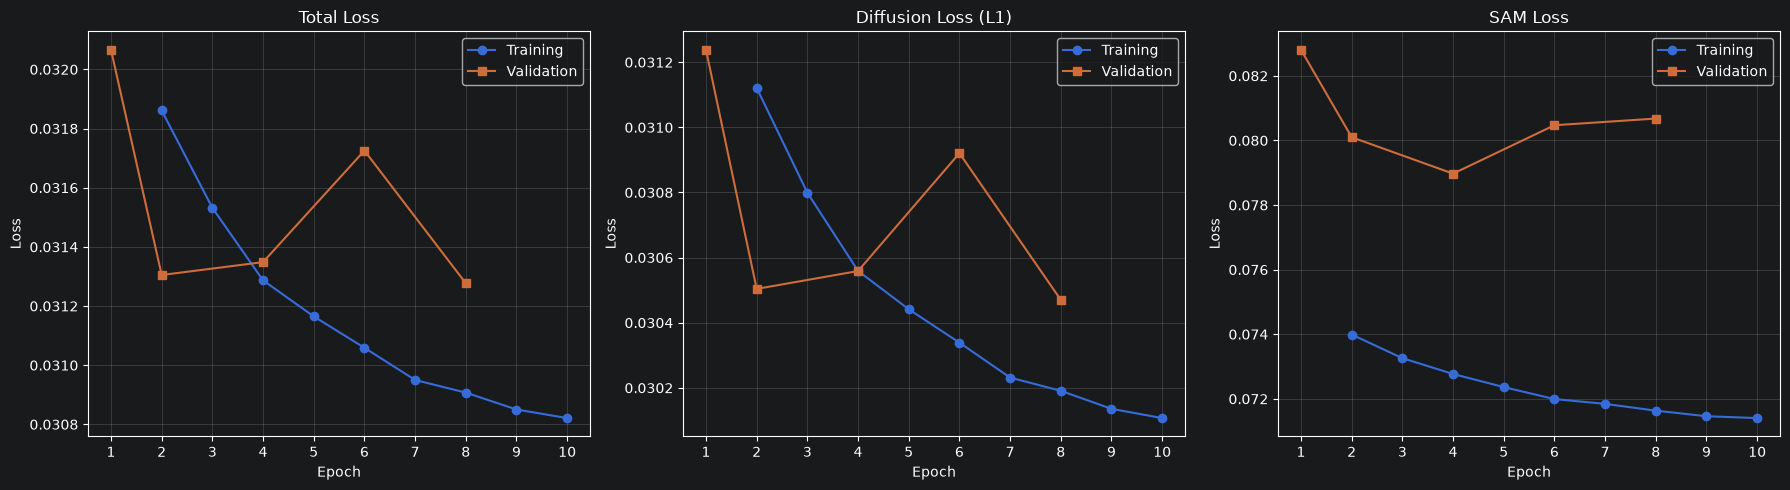

In [43]:
import matplotlib.pyplot as plt

train_epochs = list(range(2, 2 + len(history["train_total_loss"])))
val_epochs = [1, 2, 4, 6, 8, 10][:len(history["val_total_loss"])]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plots = [
    ("Total Loss", "train_total_loss", "val_total_loss"),
    ("Diffusion Loss (L1)", "train_diffusion_loss", "val_diffusion_loss"),
    ("SAM Loss", "train_sam_loss", "val_sam_loss")
]

for ax, (title, train_key, val_key) in zip(axes, plots):

    ax.plot(
        train_epochs,
        history[train_key],
        marker="o",
        label="Training"
    )

    ax.plot(
        val_epochs,
        history[val_key],
        marker="s",
        label="Validation"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(range(1, 11))
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()